### Checklist for submission

It is extremely important to make sure that:

1. Everything runs as expected (no bugs when running cells);
2. The output from each cell corresponds to its code (don't change any cell's contents without rerunning it afterwards);
3. All outputs are present (don't delete any of the outputs);
4. Fill in all the places that say `# YOUR CODE HERE`, or "**Your answer:** (fill in here)".
5. Never copy/paste any notebook cells. Inserting new cells is allowed, but it should not be necessary.
6. The notebook contains some hidden metadata which is important during our grading process. **Make sure not to corrupt any of this metadata!** The metadata may for example be corrupted if you copy/paste any notebook cells, or if you perform an unsuccessful git merge / git pull. It may also be pruned completely if using Google Colab, so watch out for this. Searching for "nbgrader" when opening the notebook in a text editor should take you to the important metadata entries.
7. Although we will try our very best to avoid this, it may happen that bugs are found after an assignment is released, and that we will push an updated version of the assignment to GitHub. If this happens, it is important that you update to the new version, while making sure the notebook metadata is properly updated as well. The safest way to make sure nothing gets messed up is to start from scratch on a clean updated version of the notebook, copy/pasting your code from the cells of the previous version into the cells of the new version.
8. If you need to have multiple parallel versions of this notebook, make sure not to move them to another directory.
9. Although not forced to work exclusively in the course `conda` environment, you need to make sure that the notebook will run in that environment, i.e. that you have not added any additional dependencies.

Failing to meet any of these requirements might lead to the submission not being validated meaning no feedback will be provided.

We advise you to perform the following steps before submission to ensure that requirements 1, 2, and 3 are always met: **Restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All). This might require a bit of time, so plan ahead for this. Finally press the "Save and Checkout" button before handing in, to make sure that all your changes are saved to this .ipynb file.

### Fill in name of notebook file
This might seem silly, but the version check below needs to know the filename of the current notebook, which is not trivial to find out programmatically.

You might want to have several parallel versions of the notebook, and it is fine to rename the notebook as long as it stays in the same directory. **However**, if you do rename it, you also need to update its own filename below:

In [1]:
nb_fname = "HA2.ipynb"

assert (nb_fname != "XXX.ipynb"), "Make sure to fill in the nb_fname variable above!"

### Fill in group number and member names:

In [2]:
NAME1 = "Mahnoor Ali Cheema"
GROUP = "25"

### Check Python version

In [3]:
from platform import python_version_tuple

assert (
    python_version_tuple()[:2] == ("3", "11")
), "You are not running Python 3.11. Make sure to run Python through the course Conda environment."

### Check that notebook server has access to all required resources, and that notebook has not moved

In [4]:
import os

nb_dirname = os.path.abspath("")
assignment_name = os.path.basename(nb_dirname)
assert assignment_name in [
    "HA1",
    "HA2",
    "HA3",
    "HA4",
], "[ERROR] The notebook appears to have been moved from its original directory"

### Verify correct nb_fname

In [5]:
from IPython.display import HTML, display

try:
    display(
        HTML(
            r'<script>if("{nb_fname}" != IPython.notebook.notebook_name) {{ alert("You have filled in nb_fname = \"{nb_fname}\", but this does not seem to match the notebook filename \"" + IPython.notebook.notebook_name + "\"."); }}</script>'.format(
                nb_fname=nb_fname
            )
        )
    )
except NameError:
    assert False, "Make sure to fill in the nb_fname variable above!"

### Verify that your notebook is up-to-date and not corrupted in any way

In [6]:
import sys

sys.path.append("..")
from ha_utils import check_notebook_uptodate_and_not_corrupted

check_notebook_uptodate_and_not_corrupted(nb_dirname, nb_fname)

Matching current notebook against the following URL:
http://raw.githubusercontent.com/dml-cth/deep-machine-learning/master/home-assignments/HA2/HA2.ipynb
[SUCCESS] No major notebook mismatch found when comparing to latest GitHub version. (There might be minor updates, but even that is the case, submitting your work based on this notebook version would be acceptable.)


# HA2 - Catching Pokemon

<div style="text-align: center;">
  <img src="https://commons.wikimedia.org/wiki/Special:FilePath/Pok%C3%A9mon_GO_logo.svg" width="400">
</div>

In this home assignment, you'll apply roughly the same principles we used when doing logistic regression on the Iris dataset in Computer Lab 1, but on a different and very interesting dataset. We'll use the [Predict'em All dataset from Kaggle](https://www.kaggle.com/semioniy/predictemall). To download the dataset you will need a Kaggle account. This dataset consists of roughly 293,000 [pokemon](http://www.pokemongo.com/) sightings (historical appearances of Pokemon in the Pokemon Go game), with geographical coordinates, time, weather, population density, distance to pokestops/gyms etc. as features. A comprehensive list of all the features is available at [the dataset's homepage](https://www.kaggle.com/semioniy/predictemall).

The context is simple: you are a Pokemon hunter, and there are only three Pokemon left for you to complete your collection. You'll do anything to capture them, including changing where you'll spend your next holidays! You know that some Pokemon only spawn in certain places of the world. Since you like machine learning so much, you figure it would be a great idea to train a classifier that, based on a location's longitude and latitude, can tell us which Pokemon is more likely to appear there.

The assignment is broken down into six steps.

1. Loading the data and extracting the desired subset of it
2. Visualization of the dataset
3. Preprocessing
4. Training
5. Evaluation
6. Exploration

Feel free to temporarily add cells wherever you see fit, and play around with this notebook as much as you want when developing the solutions. However, the solution you upload to Canvas must have the exact format shown here, with only the cells present here.

Don't restrict yourself only to what was taught so far. Some of the tasks might require you to search for new information. However, **be sure that you do the assignment using PyTorch** since we will be using it through the following assignments as well. [The Python docs](https://docs.python.org/3/), [PyTorch docs](https://pytorch.org/docs/stable/index.html), [stackoverflow](https://stackoverflow.com/), and Google are your friends!

**Hint:** Solving Computer Lab 1 (CL1) is a good way to get prepared for this assignment.

For your implementation to be correct your solutions should pass all tests (`assert`-statements). Further, similar to HA1, this notebook contains some questions where we ask you to reflect upon some results.

## 0. Imports

Import any necessary modules here.

In [7]:
# YOUR CODE HERE
import pandas as pd
import numpy as np

## 1. Loading and extracting subset

The first step consists of filtering the dataset by the three Pokémon you are interested at. 

Start by loading the `'300k.csv'` file using pandas. If you haven't downloaded it yet, either use [this link](https://www.kaggle.com/semioniy/predictemall) to do so (and place the file in the same folder as this notebook), or simply run the cell below. You might have to [create a new API token](https://www.kaggle.com/settings/account) before the commands work.

In [ ]:
!kaggle datasets download -d semioniy/predictemall
!unzip -u predictemall.zip
!rm -rf predictemall.zip 300k_arff 300k.arff 300k_csv

In [9]:
# TODO: load the dataset using pandas to a dataframe called df
df = pd.read_csv("300k.csv", low_memory=False)
df.head()

,pokemonId,latitude,longitude,appearedLocalTime,_id,cellId_90m,cellId_180m,cellId_370m,cellId_730m,cellId_1460m,...,cooc_143,cooc_144,cooc_145,cooc_146,cooc_147,cooc_148,cooc_149,cooc_150,cooc_151,class
0,16,20.525745,-97.460829,2016-09-08T03:57:45,NTgxMDkzOTk4MTM5MjUwMjIzNw==,9645139108510564000,9645139108711890000,9645139108443455000,9645139109517197000,9645139113812165000,...,False,False,False,False,False,False,False,False,False,16
1,133,20.523695,-97.461167,2016-09-08T03:57:37,OTQ1NDgzODc1MjM3NDEzMTI2MQ==,9645139109852742000,9645139109785633000,9645139110590940000,9645139109517197000,9645139113812165000,...,False,False,False,False,False,False,False,False,False,133
2,16,38.903590,-77.199780,2016-09-08T03:57:25,NTQ0OTQ0NDA1Nzg2ODg3OTg2OQ==,9923201472785285000,9923201472986612000,9923201473791918000,9923201477013144000,9923201481308110000,...,False,False,False,False,False,False,False,False,False,16
3,13,47.665903,-122.312561,2016-09-08T03:56:22,NTU2MTU1NDM4NzA2MDk1MDcxNw==,6093392705025474600,6093392705092583400,6093392705897889800,6093392702676664300,6093392715561566200,...,False,False,False,False,False,False,False,False,False,13
4,133,47.666454,-122.311628,2016-09-08T03:56:08,MTY2ODg4MTAzMTczMDE0MTUwNTM=,6093392707709829100,6093392707776938000,6093392708045373400,6093392711266598900,6093392715561566200,...,False,False,False,False,False,False,False,False,False,133


In [10]:
print("df shape: ", df.shape)
assert df.shape == (
    296021,
    208,
), f"Dataframe has not the right shape. {df.shape} != (296021, 208)"
assert isinstance(df, pd.DataFrame), f"df is not a dataframe. Was {type(df)}"

df shape:  (296021, 208)


Modify `df` to only have the columns `latitude`, `longitude`, and `class`.

In [11]:
# YOUR CODE HERE
df = df[["latitude", "longitude", "class"]]
df.head()

,latitude,longitude,class
0,20.525745,-97.460829,16
1,20.523695,-97.461167,133
2,38.903590,-77.199780,16
3,47.665903,-122.312561,13
4,47.666454,-122.311628,133


In [12]:
assert len(df.columns) == 3, "There should be 3 columns"
assert len(df.shape) == 2, "The dataframe should be 2 dimensional"
assert df.shape == (296021, 3), "Wrong shape of the dataframe"
assert "latitude" in df.columns, "latitude column is missing"
assert "longitude" in df.columns, "longitude column is missing"
assert "class" in df.columns, "class column is missing"

Note that the `class` column specifies which pokemon it is. However, it only has the numerical id of the pokemon. For your convenience, we provide the dictionary `name_dict` to convert between ids and names (we'll do this soon).

In [13]:
from utils import name_dict

In [14]:
# example usage (you can index either by name or id)
print(name_dict["Gengar"])
print(name_dict[94])

94
Gengar


In [15]:
# for convenience, let's add a new column to the dataframe with the name of the pokemon
df["name"] = df["class"].apply(lambda x: name_dict[x])
print(df.head())

    latitude   longitude  class    name
0  20.525745  -97.460829     16  Pidgey
1  20.523695  -97.461167    133   Eevee
2  38.903590  -77.199780     16  Pidgey
3  47.665903 -122.312561     13  Weedle
4  47.666454 -122.311628    133   Eevee


We are only interested in three specific pokemon: Diglett, Seel, and Tauros.

<table style="width:100%">
  <tr>
    <th> <center>Diglett</center> </th>
    <th> <center>Seel</center> </th> 
    <th> <center>Tauros</center> </th>
  </tr>
  <tr>
    <td><img src=https://assets.pokemon.com/assets/cms2/img/pokedex/full/050_f2.png alt=Digglet></td>
    <td><img src=https://www.pokemon.com/static-assets/content-assets/cms2/img/pokedex/full/086.png?version=2c32fbe0af2d0da707e5dbcb40472fbf></td>
    <td><img src=https://www.pokemon.com/static-assets/content-assets/cms2/img/pokedex/full/128.png></td>
  </tr>
</table>



Filter the dataset to contain only these three types of pokemon and save it in the DataFrame `filtered_df`.

In [16]:
filtered_df = df[df["name"].isin(["Diglett", "Seel", "Tauros"])]
print(
    f"We have {len(filtered_df)} instances of Diglett, Seel, and Tauros in the dataset."
)

We have 2083 instances of Diglett, Seel, and Tauros in the dataset.


In [17]:
assert len(np.unique(filtered_df["class"])) == 3, "There should be 3 unique classes."
assert filtered_df.shape == (
    2083,
    4,
), "The shape of the filtered dataframe is incorrect."
assert sorted(np.unique(filtered_df["class"]).tolist()) == sorted(
    list(map(name_dict.get, ["Diglett", "Seel", "Tauros"]))
)

In an earlier cell, you could see that the dataset has 208 features per pokemon sighting (`df.shape == (296021, 208)`). We will only be using the `longitude` and `latitude` features. What could be a motivation for just using these features and not all the available features? 

**Your answer:**
For this assignment, we are interested to predict location of three specific Pokemon and for that longitude and latitude features are sufficient to get spatial information and also allows us to visulaize the data and decision boundaries in 2D. Other 206 features seems irrevelant for this specific question as they are just adding up unneccessary complexity, noise, increase in computation time and make the model harder to interpret. 

## 2. Visualization of the dataset

The second step consists of visualizing the dataset. This will help you understand the distribution of the features and get an idea of how hard the task will be.

Plot a bar chart of the number of occurrences of each class.

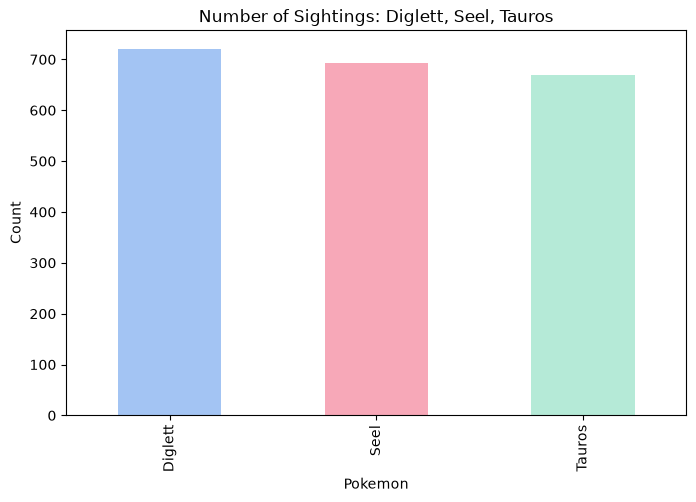

In [18]:
import matplotlib.pyplot as plt

counts = filtered_df["name"].value_counts()

plt.figure(figsize=(8,5))
counts.plot(kind="bar", color=["#A3C4F3", "#F7A8B8", "#B5EAD7"])
plt.title("Number of Sightings: Diglett, Seel, Tauros")
plt.xlabel("Pokemon")
plt.ylabel("Count")
plt.show()


Is the dataset balanced? Why/why not? Why is this important?

**Your answer:**

The dataset looks roughly balanced becuase Diglet, Seel and Tauros appear in similar quanitites. It is important to have a balanced dataset as it prevents the classifier from being biased towards one class which makes training more stable and ensures the evaluation metric which in our case is accuracy derives meaningful results. When classes have similar frequencies, the model can learn each class equally well without the need of special techniques like oversampling or class weighting.

Plot a scatter plot where the first dimension is longitude, the second is latitude, and each point is a Pokemon. Further, the color of each point should represent which Pokemon it is. Lastly, the marker at each point should be an `'x'`. Make sure to label each axis.

Hints:

- The `scatter` method from `matplotlib` accepts an argument called `c`.
- The `scatter` method also accepts an argument called `marker`.

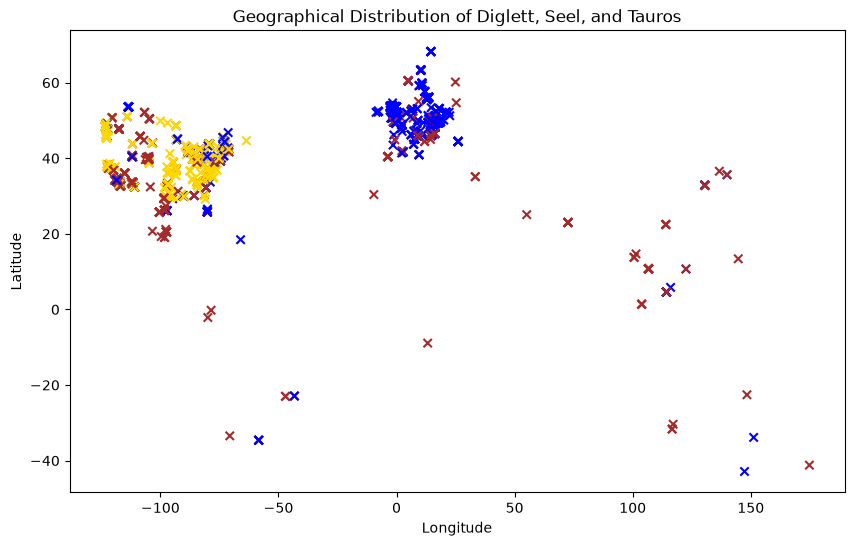

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

# Assign a color to each Pokémon
color_map = {
    "Diglett": "brown",
    "Seel": "blue",
    "Tauros": "gold"
}

# Scatter plot
plt.scatter(
    filtered_df["longitude"],
    filtered_df["latitude"],
    c=filtered_df["name"].map(color_map),
    marker='x'
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Diglett, Seel, and Tauros")
plt.show()

Is there any other visualization you think would be useful? If so, insert them here.

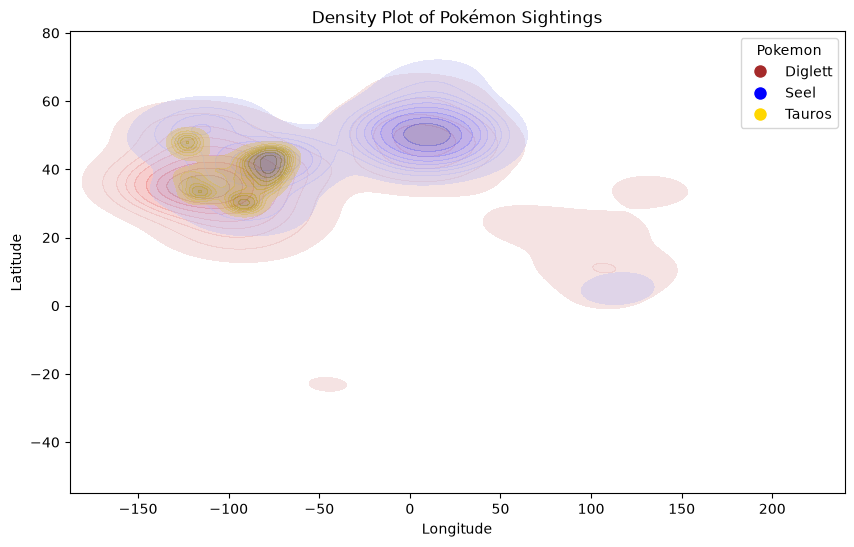

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.figure(figsize=(10,6))

# Colors for each Pokémon
color_map = {
    "Diglett": "brown",
    "Seel": "blue",
    "Tauros": "gold"
}

# Plot KDEs
for name in ["Diglett", "Seel", "Tauros"]:
    sns.kdeplot(
        data=filtered_df[filtered_df["name"] == name],
        x="longitude",
        y="latitude",
        fill=True,
        alpha=0.4,
        color=color_map[name]
    )

# Create proxy artists for legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Diglett',
           markerfacecolor='brown', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Seel',
           markerfacecolor='blue', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Tauros',
           markerfacecolor='gold', markersize=10)
]

plt.legend(handles=legend_elements, title="Pokemon")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Density Plot of Pokémon Sightings")
plt.show()

How hard do you think the problem is? Which classes can/cannot be easily separated?


**Your answer:**

The problem is fairly difficult although longitude and latitutde is providing meaningful information, but the KDE plot shows that the threee Pokemon have overlapping geographic distributions, which means the classifier won't be able to perfectly separate them using only these two features.

Based on the KDE plot, following pattern is observed:
- Diglett vs Seel are hard to seperate

  As their density regions overlap heavily which means the clusters blend together and they appear in same geographical area, classifier will struggle alot to draw a clean bouundary and this pair is hardest to distinguish therefore.

- Tauros also overlaps with both

  The density map of tauros overlaps with other two and does not form a clean isolated region and thus is not clearly seperable either.

Which accuracy do you expect to achieve?

**Your answer:**

As observed above all the three classes heavily overlap in longitude and latitude, the problem seems quite hard and it's wise to not expect high accuracy. A classifier using only these two features will likely to achieve moderate accuracy around 60 - 70%. 
The overlapping is the core here and it says that many points are inherently ambiguous so even a very good model will make mistake hence it's a natural cap to how well we can do with only location information.

## 3. Preprocessing

The third step consists of processing the data before training, such as dividing the dataset into training, validation, and test sets. Some tranformations can also be applied to the dataset in order to improve the performance of the network. We will use some PyTorch utilities to help us with this task.

Start by creating the input and output vectors, `x` and `y`. The input should be latitude and longitude, and the output should be the class of the pokemon. Note that you cannot use the class names directly, as they are strings. You need to introduce some mapping to convert them to integers (0, 1, and 2) or one-hot vectors.

In [21]:
# map names to integer labels
label_map = {"Diglett":0, "Seel":1, "Tauros":2}

# input features (longitude, latitude)
x = filtered_df[["longitude", "latitude"]].values.astype(np.float32)

# Output labels (integer encoded)
y = filtered_df["name"].map(label_map).values.astype(np.int64)

print(f"Shape of input data: {x.shape}")
print(f"Shape of labels: {y.shape}")

Shape of input data: (2083, 2)
Shape of labels: (2083,)


In [22]:
assert isinstance(x, np.ndarray), "x should be a numpy array"
assert isinstance(y, np.ndarray), "y should be a numpy array"

assert x.shape[0] == y.shape[0], "x and y should have the same number of samples"
assert x.shape[-1] == 2, "x should have 2 features"
assert x.dtype == np.float32, "x should be of type float32"
if y.shape[-1] == 3:  # one-hot encoded
    assert y.max() == 1, "one-hot encoded y, at least one entry should be 1"
    assert y.min() == 0, "one-hot encoded y, at least one entry should be 0"
    assert y.sum(axis=1).all() == 1
else:  # label encoded
    assert y.max() == 2, "label encoded y, should have a max value of 2"
    assert y.min() == 0, "label encoded y, should have a min value of 0"

Separate your data into training (55%), validation (25%) and test sets (20%) and save them as `dataset_train`, `dataset_val`, `dataset_test`. If you wish to apply any transformation to the dataset, do it here as well. 

Further, create a class, PokemonDataset, inheriting from PyTorch [`Dataset`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) and use this for storing the data. In other words, `dataset_train`, `dataset_val`, `dataset_test` should have type PokemonDataset. You will need to implement a `__getitem__`, `__len__` and `__init__` method. Although perhaps a bit overkill for this assignment, it is a good practice for handling datasets in PyTorch.

Last, instantiate a [`DataLoader`](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) for each dataset, i.e., `loader_train`, `loader_val`, `loader_test`. This will fetch samples from the datasets and combine them into batches. Remember to select a suitable batch size.

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x = scaler.fit_transform(x).astype(np.float32)


In [24]:
from sklearn.model_selection import train_test_split

# First Split: Train (55%) and temp (45%)
x_train , x_temp , y_train , y_temp  = train_test_split( x, y, test_size =0.45, random_state=42, shuffle = True)

# Second Split: Validation (25%) and test (20%)
# temp contains 45% of data and we split it into val = 25/45 ~ 0.55.., test = 20/45 ~ 0.44..
x_val , x_test , y_val, y_test = train_test_split( x_temp, y_temp , test_size =0.444 , random_state =42, shuffle= True)

import torch 
from torch.utils.data import Dataset

class PokemonDataset(Dataset):
    def __init__(self,x,y):
        self.x = torch.from_numpy(x)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

dataset_train = PokemonDataset(x_train , y_train)
dataset_val = PokemonDataset(x_val, y_val)
dataset_test = PokemonDataset(x_test, y_test)

from torch.utils.data import DataLoader

loader_train = DataLoader(dataset_train , batch_size = 32, shuffle= True)
loader_val = DataLoader(dataset_val, batch_size = 32, shuffle = False)
loader_test = DataLoader(dataset_test, batch_size =32, shuffle= False)

In [25]:
assert isinstance(
    dataset_train, PokemonDataset
), "dataset_train should be an instance of PokemonDataset"
assert isinstance(
    dataset_val, PokemonDataset
), "dataset_val should be an instance of PokemonDataset"
assert isinstance(
    dataset_test, PokemonDataset
), "dataset_test should be an instance of PokemonDataset"

assert (
    abs(len(dataset_train) / len(x) - 0.55) < 0.01
), "dataset_train has the wrong length, should be 55% of the data"
assert (
    abs(len(dataset_val) / len(x) - 0.25) < 0.01
), "dataset_val has the wrong length, should be 25% of the data"
assert (
    abs(len(dataset_test) / len(x) - 0.20) < 0.01
), "dataset_test has the wrong length, should be 20% of the data"

assert isinstance(
    loader_train, DataLoader
), "loader_train should be an instance of DataLoader"
assert isinstance(
    loader_val, DataLoader
), "loader_val should be an instance of DataLoader"
assert isinstance(
    loader_test, DataLoader
), "loader_test should be an instance of DataLoader"

assert len(loader_train), "loader_train should have a length"
assert len(loader_val), "loader_val should have a length"
assert len(loader_test), "loader_test should have a length"
assert isinstance(dataset_train, torch.utils.data.Dataset)
assert isinstance(dataset_val, torch.utils.data.Dataset)
assert isinstance(dataset_test, torch.utils.data.Dataset)

## 4. Training

The fourth step is where you will choose the architecture of your network (number of hidden layers, activation functions, etc.), optimizer, loss function and then train the network. 

Start by implementing a training loop, and a helper function to calculate the accuracy. The training loop should calculate the loss and accuracy for both the training and validation set and print it with some regular interval (each epoch, or every few epochs, for instance). It can also be helpful to plot the loss and accuracy for both the training and validation set, either in the training loop, or after it has finished (i.e., you have to store the values during training and return them).

We have prepared the `train_model` function with the arguments you need, but you have access to *args and **kwargs if you want to pass additional arguments to the function.

In [26]:
from typing import Callable, Union

import torch
import torch.nn as nn
import torch.utils


def accuracy(y_hat: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    """
    Compute the accuracy of the model.

    Args:
    y_hat: torch.Tensor: The model predictions (probability per class), shape: [batch_size, num_classes]
    y: torch.Tensor: The true labels, shape: [batch_size]

    Returns:
    torch.Tensor: The accuracy of the model
    """
    preds = torch.argmax(y_hat, dim=1)
    acc = (preds == y).float().mean()
    return acc


def train_model(
    model: nn.Module,
    optimizer: torch.optim,
    loss_fn: Union[Callable, nn.Module],
    num_epochs: int,
    train_dataloader: torch.utils.data.DataLoader,
    val_dataloader: torch.utils.data.DataLoader,
    device: Union[str, torch.device],
    *args,
    **kwargs,
):
    """
    Train the model.

    Args:
    model: nn.Module: The neural network model
    optimizer: torch.optim: The optimizer used to update the model parameters
    loss_fn: Union[Callable, nn.Module]: The loss function used to compute the loss
    num_epochs: int: The number of epochs to train the model
    train_dataloader: torch.utils.data.DataLoader: The training dataloader
    val_dataloader: torch.utils.data.DataLoader: The validation dataloader
    device: Union[str, torch.device]: The device to run the training on
    *args: Additional arguments to pass to the train function
    **kwargs: Additional keyword arguments to pass to the train function
    """
    model.to(device)

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    for epoch in range(num_epochs):
        
        # TRAINING PHASE
        model.train()
        epoch_train_loss = 0.0
        epoch_train_acc = 0.0

        for x_batch, y_batch in train_dataloader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            y_hat = model(x_batch)
            loss = loss_fn(y_hat, y_batch)
            acc = accuracy(y_hat, y_batch)

            loss.backward()
            optimizer.step()

            epoch_train_loss += loss.item()
            epoch_train_acc += acc.item()

        epoch_train_loss /= len(train_dataloader)
        epoch_train_acc /= len(train_dataloader)

       
        # VALIDATION PHASE

        model.eval()
        epoch_val_loss = 0.0
        epoch_val_acc = 0.0

        with torch.no_grad():
            for x_batch, y_batch in val_dataloader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)

                y_hat = model(x_batch)
                loss = loss_fn(y_hat, y_batch)
                acc = accuracy(y_hat, y_batch)

                epoch_val_loss += loss.item()
                epoch_val_acc += acc.item()

        epoch_val_loss /= len(val_dataloader)
        epoch_val_acc /= len(val_dataloader)

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        train_accs.append(epoch_train_acc)
        val_accs.append(epoch_val_acc)

        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}"
        )

    return train_losses, val_losses, train_accs, val_accs

Next, we'll test that your training loop is correct. A [common sanity check in deep learning](https://karpathy.github.io/2019/04/25/recipe/) is to overfit to a small dataset, like a single batch of data. This ensures that shapes and devices are correctly set, and the network can learn/memorize the training data, which is a good starting point before training on the full dataset.

In [27]:
def test_train_loop():
    import torch.nn as nn
    import torch.optim as optim
    import torch.utils.data as data

    # init simple model, optimizer, loss_fn, dataloaders
    linear_model = nn.Linear(2, 3)
    optimizer = optim.SGD(linear_model.parameters(), lr=0.01)
    loss_fn = nn.CrossEntropyLoss()
    testing_loader_train = data.DataLoader(
        data.TensorDataset(torch.randn(2, 2), torch.randint(0, 3, (2,)))
    )
    testing_loader_val = data.DataLoader(
        data.TensorDataset(torch.randn(2, 2), torch.randint(0, 3, (2,)))
    )

    # copy parameters to check for changes
    params_before_training = list(linear_model.parameters())
    params_before_training = [p.clone().to("cpu") for p in params_before_training]

    print("Testing training loop, CPU")
    train_model(
        model=linear_model,
        optimizer=optimizer,
        loss_fn=loss_fn,
        num_epochs=100,
        train_dataloader=testing_loader_train,
        val_dataloader=testing_loader_val,
        device="cpu",
    )
    if torch.cuda.is_available():
        print("Testing training loop, CUDA")
        train_model(
            model=linear_model,
            optimizer=optimizer,
            loss_fn=loss_fn,
            num_epochs=100,
            train_dataloader=testing_loader_train,
            val_dataloader=testing_loader_val,
            device="cuda" if torch.cuda.is_available() else "cpu",
        )

    params_after_training = list(linear_model.parameters())
    params_after_training = [p.clone().to("cpu") for p in params_after_training]
    for p_before, p_after in zip(params_before_training, params_after_training):
        assert torch.any(
            p_before != p_after
        ), "Model parameters did not change during training"

    # check that we could overfit a single example
    (x, y) = next(iter(testing_loader_train))
    x.to("cpu")
    y.to("cpu")
    linear_model.to("cpu")
    assert (
        linear_model(x).argmax().item() == y.item()
    ), "Model could not overfit a single example"


def test_accuracy():
    y_pred = torch.tensor([[0.1, 0.8, 0.1], [0.3, 0.4, 0.3], [0.1, 0.1, 0.8]])
    y_true = torch.tensor([1, 0, 2])
    acc = accuracy(y_pred, y_true)
    assert isinstance(acc, torch.Tensor), "Accuracy should be a torch.Tensor"
    assert torch.isclose(acc, torch.tensor(2 / 3)), f"Accuracy is {acc}, expected 2/3"


try:
    test_train_loop()
except Exception as e:
    print(e)
    assert False, "Training test failed, see error above"

test_accuracy()

Testing training loop, CPU
Epoch 1/100 | Train Loss: 1.0825 | Train Acc: 0.5000 | Val Loss: 1.3653 | Val Acc: 0.0000
Epoch 2/100 | Train Loss: 1.0445 | Train Acc: 0.5000 | Val Loss: 1.3777 | Val Acc: 0.0000
Epoch 3/100 | Train Loss: 1.0084 | Train Acc: 0.5000 | Val Loss: 1.3898 | Val Acc: 0.0000
Epoch 4/100 | Train Loss: 0.9741 | Train Acc: 0.5000 | Val Loss: 1.4017 | Val Acc: 0.0000
Epoch 5/100 | Train Loss: 0.9415 | Train Acc: 0.5000 | Val Loss: 1.4134 | Val Acc: 0.0000
Epoch 6/100 | Train Loss: 0.9105 | Train Acc: 0.5000 | Val Loss: 1.4249 | Val Acc: 0.0000
Epoch 7/100 | Train Loss: 0.8810 | Train Acc: 0.5000 | Val Loss: 1.4361 | Val Acc: 0.0000
Epoch 8/100 | Train Loss: 0.8529 | Train Acc: 0.5000 | Val Loss: 1.4471 | Val Acc: 0.0000
Epoch 9/100 | Train Loss: 0.8261 | Train Acc: 0.5000 | Val Loss: 1.4579 | Val Acc: 0.0000
Epoch 10/100 | Train Loss: 0.8006 | Train Acc: 0.5000 | Val Loss: 1.4685 | Val Acc: 0.0000
Epoch 11/100 | Train Loss: 0.7763 | Train Acc: 0.5000 | Val Loss: 1.4789

Now, create a neural network using PyTorch. You can use any architecture you want. Save the model in the variable `model`.

In [28]:
import torch
import torch.nn as nn

class PokemonNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),   # input: 2 features → 32 hidden units
            nn.ReLU(),
            nn.Linear(32, 32),  # second hidden layer
            nn.ReLU(),
            nn.Linear(32, 3)    # output: 3 classes
        )

    def forward(self, x):
        return self.net(x)

model = PokemonNet()


In [29]:
assert isinstance(model, nn.Module)


# check that we can run input of shape (batch_size, 2) through the model, with batch_size=16
def test_model_output_shape(model):
    is_model_on_cuda = next(model.parameters()).is_cuda
    device = torch.device("cuda" if is_model_on_cuda else "cpu")
    assert (
        len(model(torch.randn(16, 2, device=device))) == 16
    ), "The model should not change the batch size"


test_model_output_shape(model)

Train the network. 

For you to pass this assignment, you must obtain an accuracy on the test set greater than 60%. You can use the validation set as a proxy during development, but remember that they can differ slightly. We use the test set, as this better represents the performance of the model on new, unseen data (which is the ultimate goal).

To reach the level of performance, it may be necessary to search for a good architecture by trying several different ones. Last, if you want a challenge, try getting an accuracy greater than 75% (our reference solution achieves ~78%).

Again, it might be useful to plot the loss and accuracy (for training and validation) during training.

In [30]:
import torch
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

device = "cuda" if torch.cuda.is_available() else "cpu"

num_epochs = 50

train_losses, val_losses, train_accs, val_accs = train_model(
    model=model,
    optimizer=optimizer,
    loss_fn=loss_fn,
    num_epochs=num_epochs,
    train_dataloader=loader_train,
    val_dataloader=loader_val,
    device=device
)


Epoch 1/50 | Train Loss: 0.9050 | Train Acc: 0.5412 | Val Loss: 0.8300 | Val Acc: 0.6033
Epoch 2/50 | Train Loss: 0.7809 | Train Acc: 0.6394 | Val Loss: 0.7646 | Val Acc: 0.6632
Epoch 3/50 | Train Loss: 0.7445 | Train Acc: 0.6781 | Val Loss: 0.7759 | Val Acc: 0.6752
Epoch 4/50 | Train Loss: 0.7287 | Train Acc: 0.6988 | Val Loss: 0.7438 | Val Acc: 0.6891
Epoch 5/50 | Train Loss: 0.7208 | Train Acc: 0.7095 | Val Loss: 0.7370 | Val Acc: 0.7204
Epoch 6/50 | Train Loss: 0.7043 | Train Acc: 0.7149 | Val Loss: 0.7245 | Val Acc: 0.7185
Epoch 7/50 | Train Loss: 0.7013 | Train Acc: 0.7214 | Val Loss: 0.7271 | Val Acc: 0.7167
Epoch 8/50 | Train Loss: 0.7027 | Train Acc: 0.7166 | Val Loss: 0.7469 | Val Acc: 0.7065
Epoch 9/50 | Train Loss: 0.7038 | Train Acc: 0.7231 | Val Loss: 0.7187 | Val Acc: 0.7204
Epoch 10/50 | Train Loss: 0.6874 | Train Acc: 0.7336 | Val Loss: 0.7267 | Val Acc: 0.7167
Epoch 11/50 | Train Loss: 0.6956 | Train Acc: 0.7153 | Val Loss: 0.7702 | Val Acc: 0.7185
Epoch 12/50 | Train

In [31]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for x_batch, y_batch in loader_test:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        y_hat = model(x_batch)
        preds = torch.argmax(y_hat, dim=1)

        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

test_accuracy = correct / total
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Test Accuracy: 75.30%


Let's have a look at what we have learned! Create a function that visualizes the decision regions of the network. Overlap it with the points corresponding to the training data and validations data, such as in Section 2, by using the scatter plot function. The training and validation points should have different markers and/or colors. Last, call the function to visualize the decision regions of your network.

Hint: A simple way to show the decision region is to generate a lot of points within a predefined range of longitude and latitude and apply your network to it. However, feel free to explore other ways.

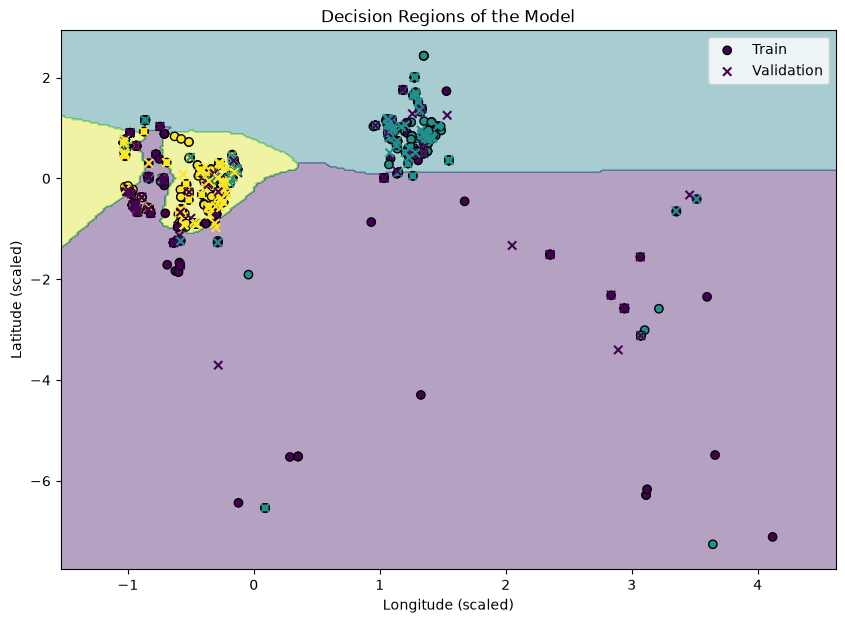

In [32]:
def plot_decision_region(model: nn.Module, x_train, y_train, x_val, y_val):
    """
    Plot the decision region of the model.

    Args:
    model: nn.Module: The trained model
    x_train: The training features, use whatever representation you prefer (e.g. numpy array, torch.Tensor, dataset, dataloader)
    y_train: The training labels, use whatever representation you prefer (e.g. numpy array, torch.Tensor, dataset, dataloader)
    x_val: The validation features, use whatever representation you prefer (e.g. numpy array, torch.Tensor, dataset, dataloader)
    y_val: The validation labels, use whatever representation you prefer (e.g. numpy array, torch.Tensor, dataset, dataloader)
    """
    # Ensure model is in eval mode
    model.eval()

    # Determine device
    device = next(model.parameters()).device

    # Convert to numpy if tensors
    if isinstance(x_train, torch.Tensor):
        x_train_np = x_train.cpu().numpy()
        y_train_np = y_train.cpu().numpy()
        x_val_np = x_val.cpu().numpy()
        y_val_np = y_val.cpu().numpy()
    else:
        x_train_np = x_train
        y_train_np = y_train
        x_val_np = x_val
        y_val_np = y_val

    # Create a grid over longitude/latitude space
    x_min, x_max = x_train_np[:,0].min() - 0.5, x_train_np[:,0].max() + 0.5
    y_min, y_max = x_train_np[:,1].min() - 0.5, x_train_np[:,1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()].astype(np.float32)
    grid_tensor = torch.from_numpy(grid).to(device)

    # Predict class for each grid point
    with torch.no_grad():
        preds = model(grid_tensor)
        preds = torch.argmax(preds, dim=1).cpu().numpy()

    # Reshape predictions to match grid
    Z = preds.reshape(xx.shape)

    # Plot decision region
    plt.figure(figsize=(10, 7))
    plt.contourf(xx, yy, Z, alpha=0.4, cmap="viridis")

    # Plot training points
    plt.scatter(
        x_train_np[:,0], x_train_np[:,1],
        c=y_train_np, cmap="viridis",
        edgecolor="black", marker="o", label="Train"
    )

    # Plot validation points
    plt.scatter(
    x_val_np[:,0], x_val_np[:,1],
    c=y_val_np, cmap="viridis",
    marker="x", label="Validation"
    )

    plt.title("Decision Regions of the Model")
    plt.xlabel("Longitude (scaled)")
    plt.ylabel("Latitude (scaled)")
    plt.legend()
    plt.show()
plot_decision_region(model, x_train, y_train, x_val, y_val)


Do the learned decision regions look like you would expect? Can they be improved? In what sense, and how would that change your model? Please comment on your results. 

**Your answer:**
Yes, the learned regions does look like how I expecthed them to be. The model is successful in seperating the three Pokemon classes in the longitude-latitude space, producing smooth, curved boundaries that reflect the underlying strcuture of data. Most of the training and vlaidation points fall inside the correct regions which indicated good geenrlaization.

The boundaries can be improved if we for example increase model capacity which mean add more layers and hidden units to the network, adjusting the learning , adjusting the leanring rate or training for more epochs.

These changes would allow the network to learn more detailed and fine decision surfaces which will potentially immporve the accuracy and will produce smoother and more precise regions.

### 4.1. Model capacity and generalization

Now we have all the neccessary tools to do a small experiment on model capacity and implications on generalization.

Begin by defining a neural network `tiny_model` with a single linear layer and appropriate activation function. Then, train the network until convergence (should be fast).

In [38]:
import torch.nn as nn

class TinyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(2, 3)   # input: 2 features, output: 3 classes

    def forward(self, x):
        return self.linear(x)           # no activation needed for logits

tiny_model = TinyModel()

# Train the tiny model
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(tiny_model.parameters(), lr=0.01)
device = "cuda" if torch.cuda.is_available() else "cpu"

train_model(
    model=tiny_model,
    optimizer=optimizer,
    loss_fn=loss_fn,
    num_epochs=100,
    train_dataloader=loader_train,
    val_dataloader=loader_val,
    device=device
)

# Evaluate on test set
tiny_model.eval()
correct = 0
total = 0

with torch.no_grad():
    for x_batch, y_batch in loader_test:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        y_hat = tiny_model(x_batch)
        preds = torch.argmax(y_hat, dim=1)

        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

test_accuracy = correct / total
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Epoch 1/100 | Train Loss: 1.1113 | Train Acc: 0.2587 | Val Loss: 0.9847 | Val Acc: 0.4114
Epoch 2/100 | Train Loss: 0.9565 | Train Acc: 0.3935 | Val Loss: 0.9328 | Val Acc: 0.3864
Epoch 3/100 | Train Loss: 0.9188 | Train Acc: 0.4018 | Val Loss: 0.9214 | Val Acc: 0.4324
Epoch 4/100 | Train Loss: 0.9077 | Train Acc: 0.4072 | Val Loss: 0.9206 | Val Acc: 0.3975
Epoch 5/100 | Train Loss: 0.9066 | Train Acc: 0.4199 | Val Loss: 0.9182 | Val Acc: 0.4085
Epoch 6/100 | Train Loss: 0.9062 | Train Acc: 0.4568 | Val Loss: 0.9194 | Val Acc: 0.4508
Epoch 7/100 | Train Loss: 0.9033 | Train Acc: 0.4493 | Val Loss: 0.9176 | Val Acc: 0.4461
Epoch 8/100 | Train Loss: 0.9043 | Train Acc: 0.4675 | Val Loss: 0.9179 | Val Acc: 0.4636
Epoch 9/100 | Train Loss: 0.9031 | Train Acc: 0.4549 | Val Loss: 0.9171 | Val Acc: 0.4534
Epoch 10/100 | Train Loss: 0.9038 | Train Acc: 0.4409 | Val Loss: 0.9191 | Val Acc: 0.4618
Epoch 11/100 | Train Loss: 0.9041 | Train Acc: 0.4725 | Val Loss: 0.9181 | Val Acc: 0.4655
Epoch 12

In [39]:
assert isinstance(tiny_model, nn.Module), "tiny_model should be a torch.nn.Module"
test_model_output_shape(tiny_model)

Now, draw the decision regions of the network as you did in the previous section. Before running the code, think about what you expect to see. What will the regions look like? How will they differ from the previous ones?

**Answer**
For the decision region of tiny model, I expect them to look very different from the previous model. It is due to the fact that tiny_model consissts of just a single linear layer and thus it can only learn linear decision boundaries. So the decision boundary  is seperated by straight lines rather curved or flexible shapes.
As the Pokemon dataset is not linearly separable, hence these straight-line boundaries does not align with the acutal clusters of data. It is safe to say that tiny model underfits and many training and validation points will fall outside their correct regions which leads to lower accuracy than larger network.
Hence through this experiment it is observed that limited model capacity restricts complexity of decison regions and reduces the model's ability to generalize to the true underlying structure of data.

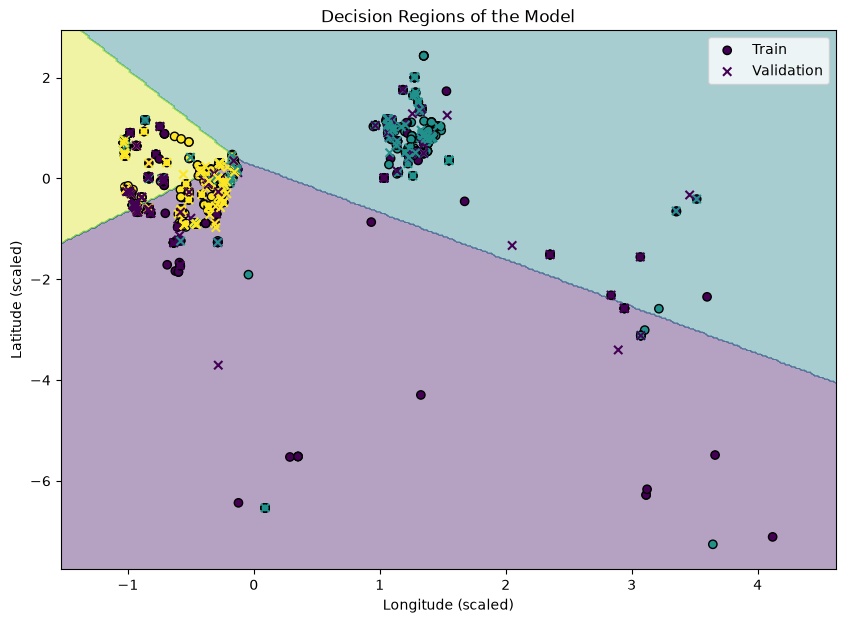

In [40]:
plot_decision_region(tiny_model, x_train, y_train, x_val, y_val)


Are the decision regions any different? Why/why not? What does this tell you about the model capacity and its ability to generalize?

**Your answer:** 

The decision regions of the tiny model are evidently different from those of the larger model as the tiny_model consissts of a single linear layer which can only learn linear decision boudaries and hence the regions are seperated by straight lines and don't take into account the curved structure of the data. 

On the other side, the larger model produced smooth, curved decison regions that align mich better with the clusters. This shows that model capacity has a direct impact on the complexity of decision boundaries a network can learn. A model with insufficient capacity can't represent the true structure of the data and therefore generalizes poorly. 

Increasing caapcity which means more layers and nonlinear activations allow the model to learn more flexible and accurate decison regions.



Next, create a neural network `large_model` with many layers and/or hidden units. Try to maximize the training accuracy (0.7-0.8). Getting these models to converge might be a bit tricky, so you might have to adjust the learning rate, the optimizer, etc. Also, might be easier to have a wide model (large number of hidden units, say 1024 per layer) than a deep model (more than 4 layers).

Feel free to experiment, but if you get stuck, our model is a MLP with an input layer, 4 hidden layers with 1024 units each, and an output layer. We used the ReLU activation function between each layer and a softmax for the output layer. We used the Adam optimizer with a learning rate of 0.003 and a batch size of 512. We trained for at least a few hundred epochs. Also, normalizing the input can be helpful (zero mean and unit variance).

In [42]:
import torch
import torch.nn as nn

class LargeModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 1024),
            nn.ReLU(),
            nn.Linear(1024, 1024),
            nn.ReLU(),
            nn.Linear(1024, 1024),
            nn.ReLU(),
            nn.Linear(1024, 1024),
            nn.ReLU(),
            nn.Linear(1024, 3)   # output layer
        )

    def forward(self, x):
        return self.net(x)

large_model = LargeModel()
#optimizer and loss
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(large_model.parameters(), lr=0.003)
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    torch.from_numpy(x_train).float(),
    torch.from_numpy(y_train).long()
)

val_dataset = TensorDataset(
    torch.from_numpy(x_val).float(),
    torch.from_numpy(y_val).long()
)

#larger batch size
loader_train_large = torch.utils.data.DataLoader(
    train_dataset, batch_size=512, shuffle=True
)
loader_val_large = torch.utils.data.DataLoader(
    val_dataset, batch_size=512, shuffle=False
)
#train for many epochs
num_epochs = 300

train_losses, val_losses, train_accs, val_accs = train_model(
    model=large_model,
    optimizer=optimizer,
    loss_fn=loss_fn,
    num_epochs=num_epochs,
    train_dataloader=loader_train_large,
    val_dataloader=loader_val_large,
    device=device
)
#evaluate on test set
large_model.eval()
correct = 0
total = 0

with torch.no_grad():
    for x_batch, y_batch in loader_test:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        y_hat = large_model(x_batch)
        preds = torch.argmax(y_hat, dim=1)

        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

test_accuracy = correct / total
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Epoch 1/300 | Train Loss: 1.7109 | Train Acc: 0.4104 | Val Loss: 1.2071 | Val Acc: 0.5493
Epoch 2/300 | Train Loss: 1.0675 | Train Acc: 0.5068 | Val Loss: 1.0027 | Val Acc: 0.5239
Epoch 3/300 | Train Loss: 0.9704 | Train Acc: 0.5024 | Val Loss: 0.8781 | Val Acc: 0.5209
Epoch 4/300 | Train Loss: 0.8746 | Train Acc: 0.5208 | Val Loss: 0.9908 | Val Acc: 0.6175
Epoch 5/300 | Train Loss: 0.8217 | Train Acc: 0.5962 | Val Loss: 0.8270 | Val Acc: 0.5991
Epoch 6/300 | Train Loss: 0.8245 | Train Acc: 0.6493 | Val Loss: 0.8514 | Val Acc: 0.6702
Epoch 7/300 | Train Loss: 0.7909 | Train Acc: 0.6657 | Val Loss: 0.8084 | Val Acc: 0.7268
Epoch 8/300 | Train Loss: 0.7411 | Train Acc: 0.7004 | Val Loss: 0.7367 | Val Acc: 0.7395
Epoch 9/300 | Train Loss: 0.7096 | Train Acc: 0.7320 | Val Loss: 0.8094 | Val Acc: 0.6859
Epoch 10/300 | Train Loss: 0.7035 | Train Acc: 0.7297 | Val Loss: 0.8132 | Val Acc: 0.7365
Epoch 11/300 | Train Loss: 0.7315 | Train Acc: 0.6953 | Val Loss: 0.7950 | Val Acc: 0.7395
Epoch 12

In [43]:
assert isinstance(large_model, nn.Module), "large_model should be a torch.nn.Module"
test_model_output_shape(large_model)

Again, draw the decision regions of the network. What do you expect to see now? How will the regions differ from the previous ones?

**Answer**
Now the regions will be no longer smoother instead they'll twist and bend to fit the traning data very closely. It may be possible to see small islands of one class inside another or very narrow strips which indicates that model is fitting fine-grained patterns. As model's capacity is high it's gonna push boundaires around individual clusters. Now the regions will look too tailored to the training and vlaidaiton points which hints to overfitting.

Previously as the model was tiny we observed linear decison boudaries and clear underfitting was observed, but for large model it is highly curved, detailed regions and overfitting is sighted. 

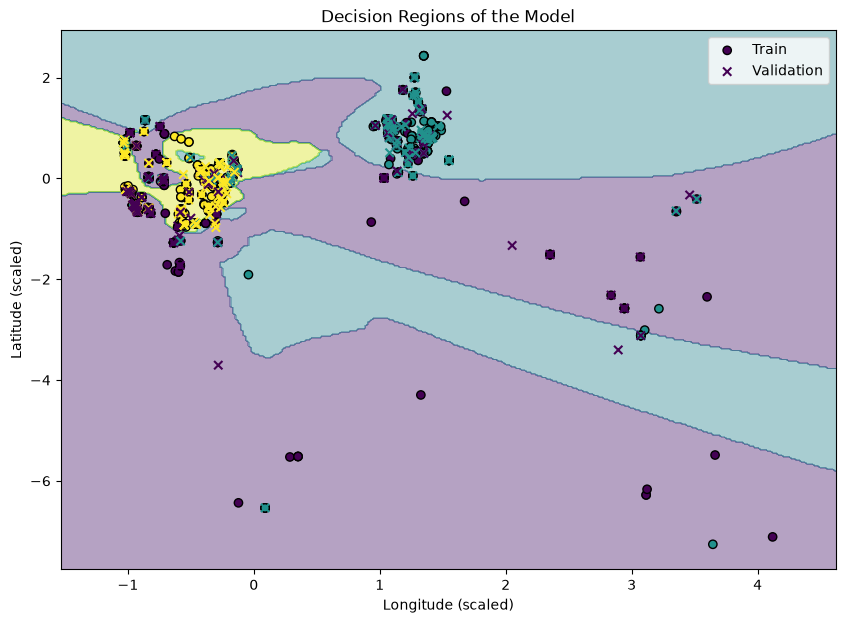

In [45]:
# Make sure the model is in evaluation mode
large_model.eval()

# Plot the decision regions
plot_decision_region(
    large_model,
    x_train, y_train,
    x_val, y_val
)


How do the decision regions differ between the tiny, large and the network you trained? Can you explain why this happens? Relate your answer to the concepts you learned in the first lectures.

**Your answer:**
The tiny model produces very simple, straight-line decision boundaries because it has extremely low capacity and can only represent linear functions. This leads to underfitting: the model cannot capture the nonlinear structure of the data, resulting in poor training and validation performance.

The medium-sized model produces smooth, curved decision regions that align well with the actual data clusters. Its capacity is well matched to the complexity of the task, allowing it to learn meaningful patterns without overfitting. This results in good generalization.

The large model produces highly irregular, overly complex decision regions with sharp bends and small pockets. This indicates overfitting: the model has so much capacity that it memorizes the training data, creating boundaries that reflect noise rather than true structure. Training accuracy is high, but generalization suffers.

These observations illustrate the bias–variance tradeoff introduced in the first lectures: small models have high bias and underfit, large models have high variance and overfit, and models with appropriate capacity achieve the best generalization

## 5. Evaluation

Back to your original model. Once you achieved at least 60% accuracy in the validation set with your main model, we are done with its training. Now we'll evaluate the performance of your classifier on the test set.

Compute the accuracy on the test set.

In [47]:
main_model_test_accuracy = 0

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for x_batch, y_batch in loader_test:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        y_hat = model(x_batch)
        preds = torch.argmax(y_hat, dim=1)

        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

main_model_test_accuracy = correct / total

print(f"Test accuracy: {main_model_test_accuracy:.3f}.")
assert main_model_test_accuracy > 0.6


Test accuracy: 0.753.


In [48]:
assert main_model_test_accuracy > 0.6

Most likely, you'll get a different (slightly worse) accuracy than the one you got on the validation set. Why is this? Also, why do we need both a test and validation set?

**Your answer:**
The test accuracy is usually slightly lower than the validation accuracy because the validation set is used during training to tune hyperparameters and decide when to stop. As a result, the model indirectly adapts to the validation set, making its performance on that set somewhat optimistic. The test set, on the other hand, is completely unseen and therefore provides a more realistic estimate of the model’s ability to generalize.

We need both a validation set and a test set because they serve different purposes. The validation set guides model selection and training decisions, while the test set is used only at the end to evaluate the final model. Without a separate test set, we would risk overfitting our hyperparameters to the validation set and obtaining an overly optimistic estimate of performance.


Next, compute the confusion matrix of your predictions on the test set and save it as `conf_mat`.

In [49]:
from sklearn.metrics import confusion_matrix
import torch

# Collect all predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for x_batch, y_batch in loader_test:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        y_hat = model(x_batch)
        preds = torch.argmax(y_hat, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

# Compute confusion matrix
conf_mat = confusion_matrix(all_labels, all_preds)
print(conf_mat)

[[106  24  16]
 [ 17  90  26]
 [ 20   0 118]]


In [50]:
assert isinstance(conf_mat, np.ndarray) or isinstance(
    conf_mat, torch.Tensor
), "conf_mat should be a numpy array or torch.Tensor"
assert conf_mat.shape == (3, 3), "conf_mat should have shape (3, 3), i.e. 3 classes"
assert np.sum(conf_mat) == len(
    dataset_test
), "conf_mat should sum up to the number of test samples"
_tmp_test_accuracy = (
    main_model_test_accuracy.cpu().detach().numpy()
    if isinstance(main_model_test_accuracy, torch.Tensor)
    else main_model_test_accuracy
)
assert np.abs(np.sum(np.diag(conf_mat)) / np.sum(conf_mat) - _tmp_test_accuracy) < 0.01

What can you conclude from the computed accuracy and confusion matrix?

**Your answer:**
The test accuracy of 75.3% indicates that the model generalizes well to unseen data. The confusion matrix shows that most predictions fall on the diagonal, meaning the classifier correctly identifies the majority of samples in each class. However, class 1 is more frequently misclassified, suggesting that it overlaps more with the other classes in the longitude–latitude feature space. Class 2 is the easiest to classify, with very few errors. Overall, the confusion matrix confirms that the model has learned meaningful decision boundaries but is limited by the inherent overlap between classes.

## 6. Exploration

You have now trained and evaluated a neural network for this particular classification task. Can you provide a brief explanation as to how you could use it to decide where to travel, if you're interested in capturing the aforementioned Pokemons?

**Your answer:** 
The trained neural network can be used to decide where to travel by evaluating which Pokémon is most likely to appear at different geographical coordinates. By feeding the model longitude–latitude pairs from various regions, we can identify areas where each Pokémon has the highest predicted probability. This effectively creates a map of likely spawn locations. If a player wants to capture a specific Pokémon, they can choose to travel to the regions where the model predicts that class most confidently. The confusion matrix also helps interpret reliability: classes with higher accuracy and fewer misclassifications provide more trustworthy travel recommendations.

Is (are) there any other feature(s) from the original dataset (e.g. hour of the day, pressure, wind speed, population density, etc.) which you think would be valuable to add as an input feature to your classifier to improve its performance? 

**Your answer:**
Yes, I believe additional features from the original dataset could improve the classifier’s performance. In particular, time‑related features such as hour of the day or day of the week could capture temporal patterns in Pokémon appearances. Weather variables like pressure, temperature, wind speed, and humidity may also be informative if certain Pokémon are more likely to appear under specific weather conditions. Furthermore, population density or an urban–rural indicator could help distinguish locations that are geographically close but very different in human activity. Adding such features would give the model a richer description of each observation, allowing it to learn more nuanced decision boundaries and potentially improve its accuracy and generalization.

To investigate your hypothesis, plot a histogram of the selected feature(s) for each one of the pokemons we're interested in. For example, if you think pressure and population density are valuable for prediction, plot 6 histograms. 3 of them will be the pressure histograms for each class ('Diglett', 'Seel' and 'Tauros'), and the other 3 will be the population density for each class.

In [55]:

df = pd.read_csv("300k.csv", low_memory=False)
print(df.columns)

Index(['pokemonId', 'latitude', 'longitude', 'appearedLocalTime', '_id',
       'cellId_90m', 'cellId_180m', 'cellId_370m', 'cellId_730m',
       'cellId_1460m',
       ...
       'cooc_143', 'cooc_144', 'cooc_145', 'cooc_146', 'cooc_147', 'cooc_148',
       'cooc_149', 'cooc_150', 'cooc_151', 'class'],
      dtype='str', length=208)


In [63]:
print(filtered_df)


         latitude   longitude  class     name
90      49.146199 -122.638105     50  Diglett
137     44.476769  -73.212749    128   Tauros
225     39.767486  -86.161068    128   Tauros
550     49.999197    9.066973     86     Seel
629     25.724382 -100.379311     50  Diglett
...           ...         ...    ...      ...
294822  34.190725 -118.490821    128   Tauros
294909  34.189895 -118.490000     86     Seel
295194  53.555035   -0.087039     86     Seel
295436  34.186898 -118.488905     86     Seel
295529  39.748243  -84.086557    128   Tauros

[2083 rows x 4 columns]


In [68]:
df["name"] = df["class"].apply(lambda x: name_dict[x])

filtered_df = df[df["name"].isin(["Diglett", "Seel", "Tauros"])]


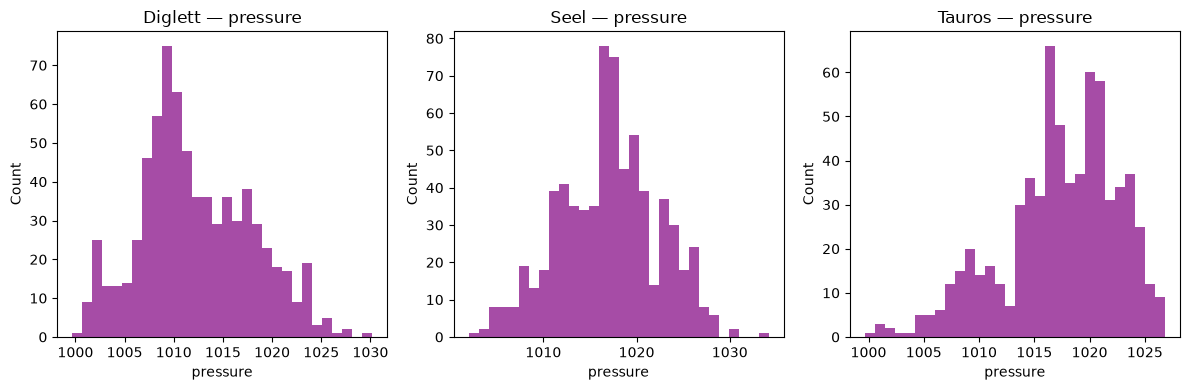

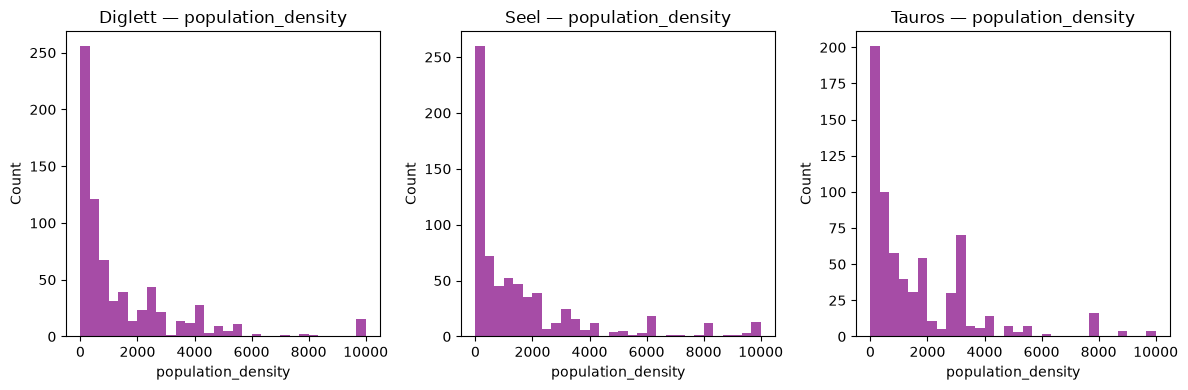

In [71]:
import matplotlib.pyplot as plt

features = ["pressure", "population_density"]
classes = ["Diglett", "Seel", "Tauros"]

for feature in features:
    plt.figure(figsize=(12, 4))

    for i, cls in enumerate(classes):
        subset = filtered_df[filtered_df["name"] == cls][feature]

        plt.subplot(1, 3, i+1)
        plt.hist(subset, bins=30, alpha=0.7, color="purple")
        plt.title(f"{cls} — {feature}")
        plt.xlabel(feature)
        plt.ylabel("Count")

    plt.tight_layout()
    plt.show()


What does/do this/these histogram(s) show you? Could it be beneficial to add this/these new feature(s) as input? Explain why/why not.

**Your answer:** 
The histograms for pressure and population density show that all three Pokémon classes occupy similar ranges for both features. There is no clear separation between Diglett, Seel, and Tauros in either variable. Because the distributions overlap heavily, these features are unlikely to help the classifier distinguish between the classes. Therefore, adding pressure or population density as input features would probably not improve model performance.

The purpose was this assignment was mostly to make you design a network for classification, using this Pokemon dataset as a use case. However, if you want to find those three particular Pokemons, most likely using a network for classification is not the best approach. An alternative would be to perform localization by using regression instead. How could we formulate this as a regression problem? **Can you state some pros and cons of approach this as a regression problem instead of a classification problem?** (We do not expect very detailed answers, the goal is to think about the pros and cons with these two different ways of formulating the problem.)

**Your answer:** 
If the real goal is simply to find Diglett, Seel, and Tauros, then treating the problem as classification isn’t ideal. A more direct approach would be to turn it into a regression task, where the model predicts where a Pokémon is likely to appear rather than which Pokémon appears at a given point. In practice, this means giving the model a Pokémon species and having it output the most likely latitude and longitude (or even a probability surface of likely spawn locations).

Thinking about the trade‑offs:
A regression approach lines up better with the actual goal, because it tells you where to go instead of just labeling a location. It can also give richer outputs, like hotspot maps or continuous probability estimates. On the other hand, Pokémon don’t spawn in one single place, they appear in many different regions,so predicting a single coordinate can be misleading. Regression also tends to be more sensitive to noise and usually requires more complex modeling to capture multiple clusters or patterns. Classification is simpler and easier to evaluate, but it doesn’t directly answer the “where should I look?” question.

## 7. (optional)

Assuming you found useful new features in the last part of this assignment, train a new classifier that uses these featues as well. Did the accuracy on the validation set improve? What's the highest accuracy you can achieve?

In [ ]:
# YOUR CODE HERE